# Phase 8 — Historical Market Data Acquisition
## Australian Stock Market Analytics

**Goal:** acquire dated daily prices for the 53 companies so a future modeling phase can define valid forward-return targets.

This notebook uses `yfinance` to request ASX symbols with the `.AX` suffix and the S&P/ASX 200 benchmark symbol `^AXJO`. Availability and ticker mappings may vary. Failed downloads are logged, not fabricated or silently filled. This is a research data source, not an official exchange feed. `auto_adjust=True` requests corporate-action-adjusted OHLC prices according to yfinance conventions. This phase acquires data only; it does not train a model or recommend trades.

## 1. Install required library

In [1]:
%pip install yfinance pandas numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   --------------- ------------------------ 0.8/2.0 MB 4.5 MB/s eta 0:00:01
   ------------------------------- -------- 1.6/2.0 MB 3.9 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 3.6 MB/s  0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ------- -------------------------------- 0.8/4.0 MB 4.1 MB/s eta 0:00:01
   --------------- ------------------------ 1.6/4.0 MB 4.2 MB/s eta 0:00:01
   ----------------------- ---------------- 2.4/4.0 MB 4.2 MB/s eta 0:00:01
   ------------------------------- -------- 3.1/4.0 MB 4.1 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 3.9 MB/s  0:00:01

   ---------------------------------------- 0/9 [pytz]
   ---------------------------------------- 0/9 [pytz]
   ---------------------------------------- 0/9 [pytz]
   ---- --------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports

In [2]:
from pathlib import Path
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Imports successful. yfinance:", getattr(yf, "__version__", "unknown"))

Imports successful. yfinance: 1.7.0


## 3. Load Phase 3 data and prepare output folders

In [3]:
INPUT_FILENAME = "australian_stocks_feature_engineered.csv"
PROJECT_ROOT = None
input_file = None
for base in [Path.cwd(), *Path.cwd().parents]:
    candidate = base / "data" / "processed" / INPUT_FILENAME
    if candidate.exists():
        PROJECT_ROOT, input_file = base, candidate
        break
if input_file is None:
    raise FileNotFoundError(f"Cannot find {INPUT_FILENAME} under data/processed/. Run Phase 3 first.")

fundamentals = pd.read_csv(input_file)
if "ticker" not in fundamentals.columns:
    raise ValueError("Phase 3 dataset must contain a ticker column.")
tickers = sorted(fundamentals["ticker"].dropna().astype(str).str.strip().str.upper().unique().tolist())
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "market_data"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "market_data"
REPORT_DIR = PROJECT_ROOT / "reports" / "market_data_acquisition"
for folder in [RAW_DIR, PROCESSED_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print("Input:", input_file)
print("Unique source tickers:", len(tickers))
print("Raw data folder:", RAW_DIR)

Input: e:\Projects\Australian Stock Market Data Science Project\data\processed\australian_stocks_feature_engineered.csv
Unique source tickers: 53
Raw data folder: e:\Projects\Australian Stock Market Data Science Project\data\raw\market_data


## 4. Configure data acquisition

In [4]:
HISTORY_PERIOD = "5y"  # Examples: 1y, 2y, 5y, 10y, max
INTERVAL = "1d"
BENCHMARK_SYMBOL = "^AXJO"
AUTO_ADJUST = True
PAUSE_SECONDS = 0.15

def to_yahoo_symbol(ticker):
    ticker = str(ticker).strip().upper()
    return ticker if "." in ticker or ticker.startswith("^") else f"{ticker}.AX"

ticker_map = pd.DataFrame({"source_ticker": tickers, "yahoo_symbol": [to_yahoo_symbol(t) for t in tickers]})
display(ticker_map.head(15))
ticker_map.to_csv(REPORT_DIR / "ticker_symbol_mapping.csv", index=False)

,source_ticker,yahoo_symbol
0,A2M,A2M.AX
1,ACL,ACL.AX
2,ADH,ADH.AX
3,AFG,AFG.AX
4,ALD,ALD.AX
5,ANN,ANN.AX
6,ANZ,ANZ.AX
7,APE,APE.AX
8,ASG,ASG.AX
9,ASH,ASH.AX


## 5. Download helper and smoke test

In [5]:
def download_one_symbol(symbol, period=HISTORY_PERIOD, interval=INTERVAL):
    try:
        data = yf.download(symbol, period=period, interval=interval, auto_adjust=AUTO_ADJUST, progress=False, threads=False)
        if data is None or data.empty:
            return None, "empty_result"
        # Flatten yfinance's MultiIndex columns if returned.
        if isinstance(data.columns, pd.MultiIndex):
            data.columns = [str(col[0]) for col in data.columns]
        data = data.reset_index()
        data = data.rename(columns={data.columns[0]: "Date"})
        data["Date"] = pd.to_datetime(data["Date"], errors="coerce", utc=True).dt.tz_localize(None)
        data = data.dropna(subset=["Date"]).sort_values("Date")
        data["ticker_symbol"] = symbol
        return data, None
    except Exception as exc:
        return None, f"{type(exc).__name__}: {exc}"

test_symbol = ticker_map.iloc[0]["yahoo_symbol"] if len(ticker_map) else BENCHMARK_SYMBOL
test_data, test_error = download_one_symbol(test_symbol, period="1mo")
print("Smoke test:", test_symbol, "error:", test_error)
if test_data is not None:
    print("Rows returned:", len(test_data))
    display(test_data.head())

Smoke test: A2M.AX error: None
Rows returned: 21


,Date,Close,High,Low,Open,Volume,ticker_symbol
0,2026-09-21,6.6800,6.8000,6.6200,6.6200,1722532,A2M.AX
1,2026-09-22,6.5500,6.7800,6.5450,6.6900,2711626,A2M.AX
2,2026-09-23,6.5700,6.7000,6.5400,6.5500,2664586,A2M.AX
3,2026-09-24,6.5700,6.6250,6.4850,6.4900,1707287,A2M.AX
4,2026-09-25,6.6500,6.6800,6.5300,6.5600,1041483,A2M.AX


## 6. Download daily data for each company

In [6]:
downloaded_frames = []
log_rows = []
for i, row in ticker_map.iterrows():
    source_ticker, symbol = row["source_ticker"], row["yahoo_symbol"]
    data, error = download_one_symbol(symbol)
    if data is not None and not data.empty:
        data["source_ticker"] = source_ticker
        downloaded_frames.append(data)
        safe_name = symbol.replace("^", "").replace(".", "_")
        data.to_csv(RAW_DIR / f"{safe_name}_daily.csv", index=False)
        status, nrows = "success", len(data)
        first_date, last_date = data["Date"].min(), data["Date"].max()
    else:
        status, nrows = "failed", 0
        first_date, last_date = pd.NaT, pd.NaT
    log_rows.append({"source_ticker": source_ticker, "yahoo_symbol": symbol, "status": status, "rows_downloaded": nrows, "first_date": first_date, "last_date": last_date, "error": error})
    print(f"[{len(log_rows)}/{len(ticker_map)}] {symbol}: {status} ({nrows} rows)")
    time.sleep(PAUSE_SECONDS)

download_log = pd.DataFrame(log_rows)
download_log.to_csv(REPORT_DIR / "company_download_log.csv", index=False)
if not downloaded_frames:
    raise RuntimeError("No company prices downloaded. Review the download log, network access, and ticker mapping.")
prices = pd.concat(downloaded_frames, ignore_index=True)
print("Successful:", int((download_log.status == "success").sum()), "Failed:", int((download_log.status != "success").sum()))
print("Raw rows:", len(prices))
display(download_log.head(20))

[1/53] A2M.AX: success (1265 rows)
[2/53] ACL.AX: success (1265 rows)
[3/53] ADH.AX: success (1265 rows)
[4/53] AFG.AX: success (1265 rows)
[5/53] ALD.AX: success (1265 rows)
[6/53] ANN.AX: success (1265 rows)
[7/53] ANZ.AX: success (1265 rows)
[8/53] APE.AX: success (1265 rows)
[9/53] ASG.AX: success (1265 rows)
[10/53] ASH.AX: success (1265 rows)
[11/53] AX1.AX: success (1265 rows)
[12/53] BEN.AX: success (1265 rows)
[13/53] BGA.AX: success (1265 rows)
[14/53] BOQ.AX: success (1265 rows)
[15/53] BRG.AX: success (1265 rows)
[16/53] CBA.AX: success (1265 rows)


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: CFK.AX"}}}
$CFK.AX: No data found, symbol may be delisted

1 Failed download:
['CFK.AX']: No data found, symbol may be delisted


[17/53] CFK.AX: failed (0 rows)
[18/53] COL.AX: success (1265 rows)
[19/53] DDR.AX: success (1265 rows)
[20/53] ELD.AX: success (1265 rows)
[21/53] FMG.AX: success (1265 rows)
[22/53] GAP.AX: success (1265 rows)
[23/53] GNC.AX: success (1265 rows)
[24/53] HLI.AX: success (1265 rows)
[25/53] HVN.AX: success (1265 rows)
[26/53] IAG.AX: success (1265 rows)
[27/53] JBH.AX: success (1265 rows)
[28/53] KGN.AX: success (1265 rows)
[29/53] KMD.AX: success (1265 rows)
[30/53] LAU.AX: success (1265 rows)
[31/53] MQG.AX: success (1265 rows)
[32/53] MTO.AX: success (1265 rows)
[33/53] NAB.AX: success (1265 rows)
[34/53] NTD.AX: success (1265 rows)
[35/53] ORA.AX: success (1265 rows)
[36/53] PLS.AX: success (1265 rows)
[37/53] PTL.AX: success (1265 rows)
[38/53] PWR.AX: success (1265 rows)
[39/53] QBE.AX: success (1265 rows)
[40/53] REH.AX: success (1265 rows)
[41/53] RIO.AX: success (1265 rows)
[42/53] SGLLV.AX: success (1265 rows)
[43/53] SGM.AX: success (1265 rows)
[44/53] SIG.AX: success (1265 

,source_ticker,yahoo_symbol,status,rows_downloaded,first_date,last_date,error
0,A2M,A2M.AX,success,1265,2021-10-19,2026-10-19,NaN
1,ACL,ACL.AX,success,1265,2021-10-19,2026-10-19,NaN
2,ADH,ADH.AX,success,1265,2021-10-19,2026-10-19,NaN
3,AFG,AFG.AX,success,1265,2021-10-19,2026-10-19,NaN
4,ALD,ALD.AX,success,1265,2021-10-19,2026-10-19,NaN
5,ANN,ANN.AX,success,1265,2021-10-19,2026-10-19,NaN
6,ANZ,ANZ.AX,success,1265,2021-10-19,2026-10-19,NaN
7,APE,APE.AX,success,1265,2021-10-19,2026-10-19,NaN
8,ASG,ASG.AX,success,1265,2021-10-19,2026-10-19,NaN
9,ASH,ASH.AX,success,1265,2021-10-19,2026-10-19,NaN


## 7. Download the ASX 200 benchmark

In [7]:
benchmark_data, benchmark_error = download_one_symbol(BENCHMARK_SYMBOL)
if benchmark_data is not None and not benchmark_data.empty:
    benchmark_data["source_ticker"] = "ASX200_BENCHMARK"
    benchmark_data.to_csv(RAW_DIR / "ASX200_benchmark_daily.csv", index=False)
    benchmark_status = "success"
    print("Benchmark rows:", len(benchmark_data))
else:
    benchmark_status = "failed"
    print("Benchmark download failed:", benchmark_error)
pd.DataFrame([{"benchmark_symbol": BENCHMARK_SYMBOL, "status": benchmark_status, "rows_downloaded": 0 if benchmark_data is None else len(benchmark_data), "error": benchmark_error}]).to_csv(REPORT_DIR / "benchmark_download_log.csv", index=False)

Benchmark rows: 1265


## 8. Standardize consolidated company data

In [8]:
prices.columns = [str(col).strip().replace(" ", "_").lower() for col in prices.columns]
prices = prices.rename(columns={"date": "date", "ticker_symbol": "yahoo_symbol", "source_ticker": "ticker"})
if "date" not in prices.columns or "ticker" not in prices.columns:
    raise ValueError(f"Expected date and ticker columns; found {prices.columns.tolist()}")
prices["date"] = pd.to_datetime(prices["date"], errors="coerce")
prices = prices.dropna(subset=["date", "ticker"]).sort_values(["ticker", "date"]).reset_index(drop=True)
for col in ["open", "high", "low", "close", "volume"]:
    if col in prices.columns:
        prices[col] = pd.to_numeric(prices[col], errors="coerce")
print("Shape:", prices.shape)
print("Unique tickers:", prices["ticker"].nunique())
print("Date range:", prices.date.min(), "to", prices.date.max())
display(prices.head())

Shape: (65771, 8)
Unique tickers: 52
Date range: 2021-10-19 00:00:00 to 2026-10-19 00:00:00


,date,close,high,low,open,volume,yahoo_symbol,ticker
0,2021-10-19,6.4581,6.4674,6.1431,6.1431,5232326,A2M.AX,A2M
1,2021-10-20,6.8473,6.9029,6.4859,6.5323,15237359,A2M.AX,A2M
2,2021-10-21,6.6064,6.8473,6.5693,6.8473,6015791,A2M.AX,A2M
3,2021-10-22,6.3840,6.5971,6.3470,6.5971,6359080,A2M.AX,A2M
4,2021-10-25,6.3006,6.4396,6.2728,6.3933,4083248,A2M.AX,A2M


## 9. Data quality and coverage checks

In [9]:
quality = {
    "rows": int(len(prices)),
    "unique_tickers": int(prices["ticker"].nunique()),
    "duplicate_ticker_date_rows": int(prices.duplicated(["ticker", "date"]).sum()),
    "date_min": str(prices["date"].min()),
    "date_max": str(prices["date"].max()),
}
for col in ["open", "high", "low", "close", "volume"]:
    if col in prices.columns:
        quality[f"missing_{col}"] = int(prices[col].isna().sum())
if {"high", "low"}.issubset(prices.columns):
    quality["high_below_low_rows"] = int((prices["high"] < prices["low"]).fillna(False).sum())
if "close" in prices.columns:
    quality["nonpositive_close_rows"] = int((prices["close"] <= 0).fillna(False).sum())
display(pd.DataFrame([quality]).T.rename(columns={0: "value"}))
pd.DataFrame([quality]).to_csv(REPORT_DIR / "market_data_quality_summary.csv", index=False)
duplicates = prices[prices.duplicated(["ticker", "date"], keep=False)].sort_values(["ticker", "date"])
duplicates.to_csv(REPORT_DIR / "duplicate_ticker_date_rows.csv", index=False)

coverage = prices.groupby("ticker").agg(rows=("date", "size"), first_date=("date", "min"), last_date=("date", "max"), unique_dates=("date", "nunique")).reset_index()
coverage["calendar_days_covered"] = (coverage["last_date"] - coverage["first_date"]).dt.days
coverage.to_csv(REPORT_DIR / "ticker_history_coverage.csv", index=False)
display(coverage.sort_values("rows").head(15))

,value
rows,65771
unique_tickers,52
duplicate_ticker_date_rows,0
date_min,2021-10-19 00:00:00
date_max,2026-10-19 00:00:00
missing_open,0
missing_high,0
missing_low,0
missing_close,0
missing_volume,0


,ticker,rows,first_date,last_date,unique_dates,calendar_days_covered
43,STP,1256,2021-11-01,2026-10-19,1256,1813
0,A2M,1265,2021-10-19,2026-10-19,1265,1826
2,ADH,1265,2021-10-19,2026-10-19,1265,1826
1,ACL,1265,2021-10-19,2026-10-19,1265,1826
4,ALD,1265,2021-10-19,2026-10-19,1265,1826
5,ANN,1265,2021-10-19,2026-10-19,1265,1826
6,ANZ,1265,2021-10-19,2026-10-19,1265,1826
3,AFG,1265,2021-10-19,2026-10-19,1265,1826
8,ASG,1265,2021-10-19,2026-10-19,1265,1826
9,ASH,1265,2021-10-19,2026-10-19,1265,1826


## 10. Visualize sample price series

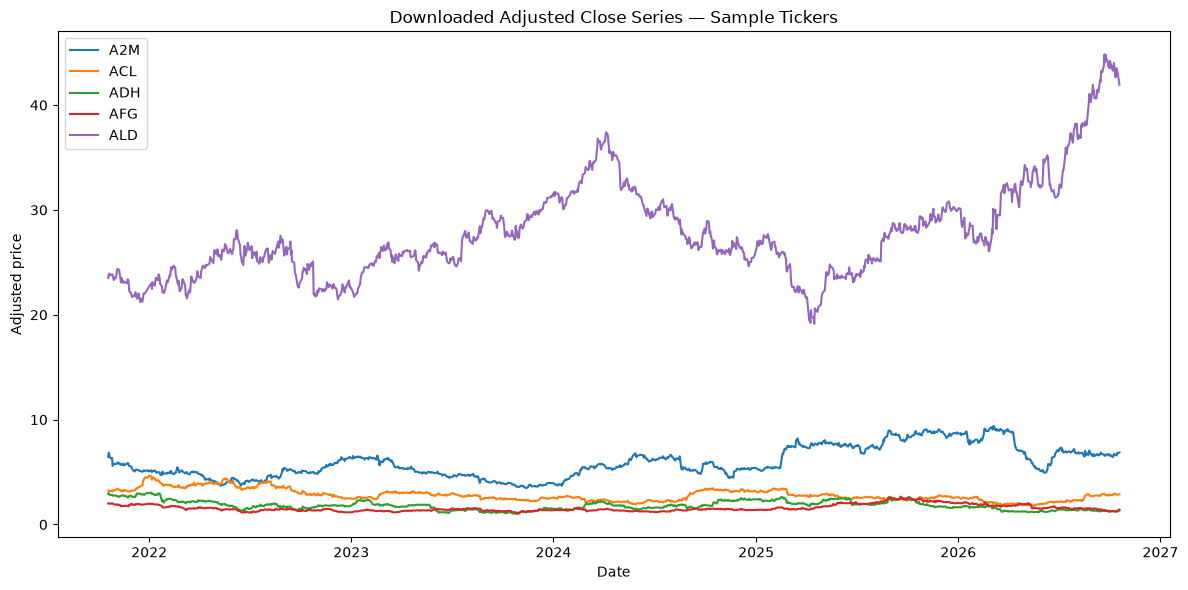

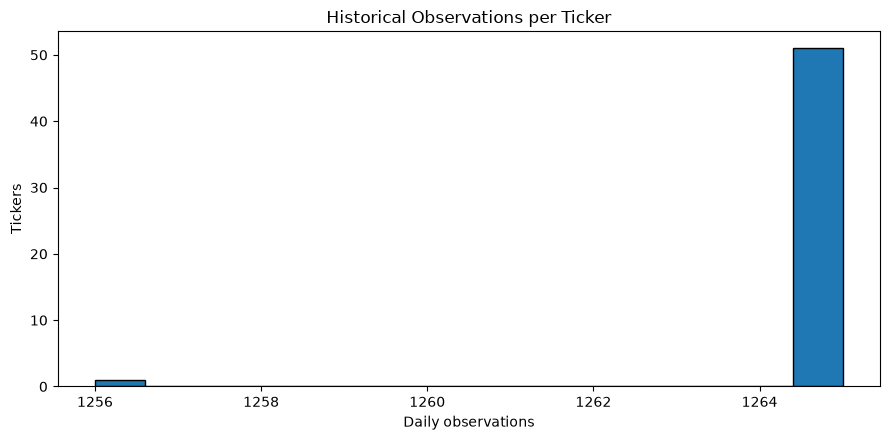

In [10]:
sample_tickers = coverage.sort_values("rows", ascending=False)["ticker"].head(5).tolist()
if "close" in prices.columns:
    fig, ax = plt.subplots(figsize=(12, 6))
    for ticker in sample_tickers:
        part = prices.loc[prices["ticker"] == ticker].sort_values("date")
        ax.plot(part["date"], part["close"], label=ticker)
    ax.set(title="Downloaded Adjusted Close Series — Sample Tickers", xlabel="Date", ylabel="Adjusted price")
    ax.legend()
    plt.tight_layout()
    plt.show()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(coverage["rows"], bins=15, edgecolor="black")
ax.set(title="Historical Observations per Ticker", xlabel="Daily observations", ylabel="Tickers")
plt.tight_layout()
plt.show()

## 11. Save consolidated datasets and final summary

In [11]:
processed_file = PROCESSED_DIR / "asx_company_daily_prices.csv"
prices.to_csv(processed_file, index=False)
if benchmark_data is not None and not benchmark_data.empty:
    bench = benchmark_data.copy()
    bench.columns = [str(col).strip().replace(" ", "_").lower() for col in bench.columns]
    bench = bench.rename(columns={"ticker_symbol": "yahoo_symbol", "source_ticker": "ticker"})
    bench.to_csv(PROCESSED_DIR / "asx200_benchmark_daily.csv", index=False)

summary = pd.DataFrame([{"requested_company_tickers": len(ticker_map), "successful_company_tickers": int((download_log.status == "success").sum()), "failed_company_tickers": int((download_log.status != "success").sum()), "combined_price_rows": len(prices), "unique_tickers_in_output": prices["ticker"].nunique(), "duplicate_ticker_date_rows": int(prices.duplicated(["ticker", "date"]).sum()), "benchmark_status": benchmark_status, "history_period_requested": HISTORY_PERIOD, "interval": INTERVAL, "auto_adjust": AUTO_ADJUST, "date_min": str(prices["date"].min()), "date_max": str(prices["date"].max())}])
display(summary)
summary.to_csv(REPORT_DIR / "market_data_acquisition_summary.csv", index=False)
print("Company price data saved to:", processed_file)
print("Reports saved to:", REPORT_DIR)
print("PHASE 8 DATA ACQUISITION FINISHED.")
print("Review failed tickers, date coverage, duplicate dates, and benchmark availability before defining future-return targets.")

,requested_company_tickers,successful_company_tickers,failed_company_tickers,combined_price_rows,unique_tickers_in_output,duplicate_ticker_date_rows,benchmark_status,history_period_requested,interval,auto_adjust,date_min,date_max
0,53,52,1,65771,52,0,success,5y,1d,True,2021-10-19 00:00:00,2026-10-19 00:00:00


Company price data saved to: e:\Projects\Australian Stock Market Data Science Project\data\processed\market_data\asx_company_daily_prices.csv
Reports saved to: e:\Projects\Australian Stock Market Data Science Project\reports\market_data_acquisition
PHASE 8 DATA ACQUISITION FINISHED.
Review failed tickers, date coverage, duplicate dates, and benchmark availability before defining future-return targets.
